In [5]:
from pathlib import Path
import os
import shutil

print(shutil.which("latex"))
print(shutil.which("pdflatex"))
import matplotlib.colors as mcolors
import matplotlib.pyplot as plt
import matplotlib.ticker as ticker
import numpy as np

output_root = Path("../Sim_Data/QCD_MC")
summary_file = output_root / "qcd_mc.npz"

plot_dir = Path("Plots/NSC_pert/ALP_perturbations/QCD_axion")
plot_dir.mkdir(parents=True, exist_ok=True)

plt.rcParams.update({
    "pdf.fonttype": 42,
    "text.usetex": True,
    "text.latex.preamble": r"\usepackage{amsmath, amssymb}",
    "font.family": "serif",
    "font.size": 16,
    "axes.labelsize": 20,
    "axes.titlesize": 18,
    "legend.fontsize": 14,
    "xtick.labelsize": 16,
    "ytick.labelsize": 16,
})

with np.load(summary_file, allow_pickle=True) as data:
    T_RH = np.asarray(data["T_RH"], dtype=float)
    ma0_ev = np.asarray(data["ma0_ev"], dtype=float)
    kappas = np.asarray(data["kappas"], dtype=float)
    delta_a_eq = np.asarray(data["delta_a_eq"], dtype=float)
    x_eq = np.asarray(data["x_eq"], dtype=float)
    kappa_J_eq = np.asarray(data["kappa_J_eq"], dtype=float)/4.5
    kappa_osc = np.asarray(data["kappa_osc"], dtype=float)
    kappa_l = np.asarray(data["kappa_l"], dtype=float)
    R_RH = np.asarray(data["R_RH"], dtype=float)
    k_RH = np.asarray(data["k_RH"], dtype=float)
    inputs = data["inputs"].item()

if delta_a_eq.shape != (len(T_RH), len(kappas)):
    raise RuntimeError(f"Unexpected delta_a_eq shape: {delta_a_eq.shape}")

kappa_nl = np.full(len(T_RH), np.nan)
peak = 1

for i, (delta, k_J) in enumerate(zip(delta_a_eq, kappa_J_eq)):
    crossing = np.where((delta[:-1] < peak) & (delta[1:] >= peak))[0]
    if len(crossing) == 0:
        continue

    j = crossing[0]
    k1, k2 = kappas[j], kappas[j + 1]
    y1, y2 = delta[j], delta[j + 1]

    if y1 <= 0.0 or y2 <= 0.0:
        continue

    log_k = np.log10(k1) - np.log10(y1) * (np.log10(k2) - np.log10(k1)) / (np.log10(y2) - np.log10(y1))
    k_cross = 10.0**log_k

    if k_cross <= k_J:
        kappa_nl[i] = k_cross

sort_idx = np.argsort(ma0_ev)

ma0_s = ma0_ev[sort_idx]
T_RH_s = T_RH[sort_idx]
delta_a_eq_s = delta_a_eq[sort_idx]
x_eq_s = x_eq[sort_idx]
kappa_J_eq_s = kappa_J_eq[sort_idx]
kappa_osc_s = kappa_osc[sort_idx]
kappa_l_s = kappa_l[sort_idx]
R_RH_s = R_RH[sort_idx]
k_RH_s = k_RH[sort_idx]
kappa_nl_s = kappa_nl[sort_idx]

T_eq = 0.79e-9
gstar_eq = 3.36
dm_fraction_eq = 0.8
M_solar_GeV = 1.115e57

rho_eq = dm_fraction_eq * gstar_eq * np.pi**2 * T_eq**4 / 30.0

M_mc_solar_s = np.full_like(ma0_s, np.nan)
valid_mc = np.isfinite(kappa_nl_s) & (kappa_nl_s > 0.0)

k_nl = kappa_nl_s[valid_mc] * k_RH_s[valid_mc]
r_nl = x_eq_s[valid_mc] * R_RH_s[valid_mc] * np.pi / (2.0 * k_nl)
M_mc = (8.0 * np.pi / 3.0) * rho_eq * r_nl**3
M_mc_solar_s[valid_mc] = M_mc / M_solar_GeV


/usr/bin/latex
/usr/bin/pdflatex


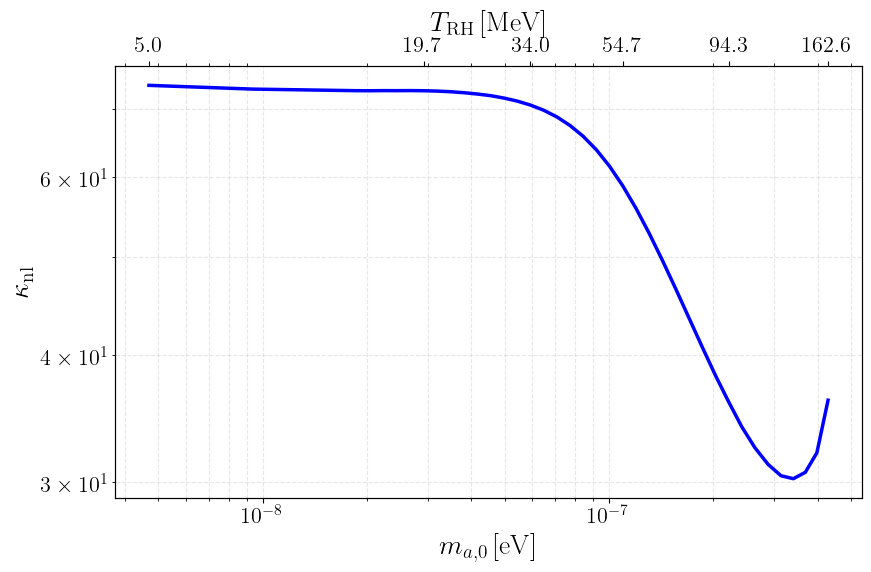

In [6]:
valid = np.isfinite(kappa_nl_s)

ma_v = ma0_s[valid]
T_v = T_RH_s[valid] * 1e3
kappa_nl_v = kappa_nl_s[valid]

fig, ax1 = plt.subplots(figsize=(9, 6))

ax1.plot(ma_v, kappa_nl_v, color="blue", lw=2.5)
ax1.set_xscale("log")
ax1.set_yscale("log")
ax1.set_xlabel(r"$m_{a,0}\,[\mathrm{eV}]$")
ax1.set_ylabel(r"$\kappa_{\rm nl}$")
ax1.grid(True, which="both", ls="--", alpha=0.3)

ax2 = ax1.twiny()
ax2.set_xscale("log")
ax2.set_xlim(ax1.get_xlim())

n_ticks = min(6, len(ma_v))
idx_ticks = np.linspace(0, len(ma_v) - 1, n_ticks, dtype=int)
ax2.set_xticks(ma_v[idx_ticks])
ax2.set_xticklabels([f"{T_v[i]:.1f}" for i in idx_ticks])
ax2.set_xlabel(r"$T_{\rm RH}\,[\mathrm{MeV}]$")

plt.tight_layout()
plt.show()


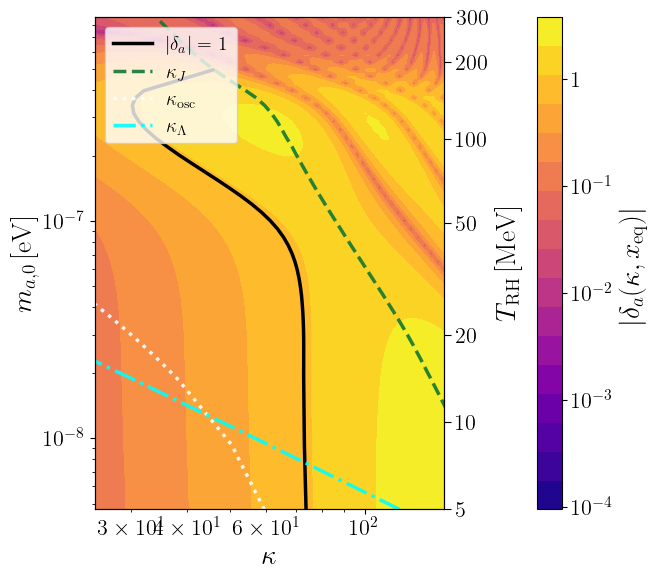

In [7]:
kappa_vals = kappas
ma0_vals = ma0_s
delta_eq_vals = delta_a_eq_s

kappa_grid, ma0_grid = np.meshgrid(kappa_vals, ma0_vals)

delta_positive = delta_eq_vals[np.isfinite(delta_eq_vals) & (delta_eq_vals > 0.0)]
delta_min = delta_positive.min()
delta_max = delta_positive.max()

delta_eq_masked = np.ma.masked_where(~np.isfinite(delta_eq_vals) | (delta_eq_vals <= 0.0), delta_eq_vals)

valid_idx = np.where(
    np.isfinite(kappa_nl_s)
    & np.isfinite(kappa_J_eq_s)
    & np.isfinite(ma0_vals)
    & (kappa_nl_s > 0.0)
    & (kappa_J_eq_s > 0.0)
    & (ma0_vals > 0.0)
)[0]

if len(valid_idx) < 2:
    raise RuntimeError("Need at least two valid nonlinear crossings to build the extrapolated boundary")

i1, i2 = valid_idx[-2], valid_idx[-1]

log_m1, log_m2 = np.log10(ma0_vals[i1]), np.log10(ma0_vals[i2])
log_knl1, log_knl2 = np.log10(kappa_nl_s[i1]), np.log10(kappa_nl_s[i2])
log_kj1, log_kj2 = np.log10(kappa_J_eq_s[i1]), np.log10(kappa_J_eq_s[i2])

slope_knl = (log_knl2 - log_knl1) / (log_m2 - log_m1)
slope_kj = (log_kj2 - log_kj1) / (log_m2 - log_m1)

if np.isclose(slope_knl, slope_kj):
    raise RuntimeError("kappa_nl and kappa_J have parallel extrapolations")

log_m_cross = log_m1 + (log_kj1 - log_knl1) / (slope_knl - slope_kj)
log_k_cross = log_knl1 + slope_knl * (log_m_cross - log_m1)

kappa_nl_plot = np.append(kappa_nl_s[valid_idx], 10.0**log_k_cross)
ma0_nl_plot = np.append(ma0_vals[valid_idx], 10.0**log_m_cross)

fig, ax = plt.subplots(figsize=(8, 6))

norm = mcolors.LogNorm(vmin=delta_min, vmax=delta_max)
levels = np.logspace(np.log10(delta_min), np.log10(delta_max), 18)
contour = ax.contourf(kappa_grid, ma0_grid, delta_eq_masked, levels=levels, norm=norm, cmap="plasma")

def log_formatter(val, pos):
    if val <= 0.0 or not np.isfinite(val):
        return ""
    if np.isclose(val, 1.0):
        return r"$1$"
    if np.isclose(val, 10.0):
        return r"$10$"

    exp = int(np.floor(np.log10(val)))
    coeff = val / 10.0**exp

    if np.isclose(coeff, 1.0):
        return rf"$10^{{{exp}}}$"

    return rf"${coeff:g}\times10^{{{exp}}}$"

cbar = fig.colorbar(contour, ax=ax, pad=0.18)
cbar.ax.yaxis.set_major_locator(ticker.LogLocator(base=10.0, numticks=10))
cbar.ax.yaxis.set_major_formatter(ticker.FuncFormatter(log_formatter))
cbar.ax.yaxis.set_minor_locator(ticker.NullLocator())
cbar.ax.yaxis.set_minor_formatter(ticker.NullFormatter())
cbar.set_label(r"$|\delta_a(\kappa,x_{\rm eq})|$")

ax.plot(kappa_nl_plot, ma0_nl_plot, color="black", ls="-", lw=2.5, label=r"$|\delta_a|=1$")
ax.plot(kappa_J_eq_s, ma0_vals, color="#117733", ls="--", lw=2.5, alpha=0.9, label=r"$\kappa_J$")
ax.plot(kappa_osc_s, ma0_vals, color="white", ls=":", lw=2.5, alpha=0.9, label=r"$\kappa_{\rm osc}$")
ax.plot(kappa_l_s, ma0_vals, color="#00FFFF", ls="-.", lw=2.5, alpha=0.9, label=r"$\kappa_\Lambda$")

ax.set_xscale("log")
ax.set_yscale("log")
ax.set_xlim(kappa_vals.min(), kappa_vals.max())
ax.set_ylim(ma0_vals.min(), ma0_vals.max())
ax.set_xlabel(r"$\kappa$")
ax.set_ylabel(r"$m_{a,0}\,[\mathrm{eV}]$")
ax.legend(loc="upper left")

ax_temp = ax.twinx()
ax_temp.set_yscale("log")
ax_temp.set_ylim(ax.get_ylim())

T_vals = T_RH_s * 1e3
temp_idx = np.argsort(T_vals)
T_sorted = T_vals[temp_idx]
ma_sorted = ma0_vals[temp_idx]

valid_temp = np.isfinite(T_sorted) & np.isfinite(ma_sorted) & (T_sorted > 0.0) & (ma_sorted > 0.0)
T_sorted = T_sorted[valid_temp]
ma_sorted = ma_sorted[valid_temp]

T_ticks = np.array([5, 10, 20, 50, 100, 200, 300], dtype=float)
T_ticks = T_ticks[(T_ticks >= T_sorted.min()) & (T_ticks <= T_sorted.max())]
tick_pos = 10.0**np.interp(np.log10(T_ticks), np.log10(T_sorted), np.log10(ma_sorted))

ax_temp.yaxis.set_major_locator(ticker.FixedLocator(tick_pos))
ax_temp.yaxis.set_major_formatter(ticker.FixedFormatter([rf"${int(T)}$" for T in T_ticks]))
ax_temp.yaxis.set_minor_locator(ticker.NullLocator())
ax_temp.yaxis.set_minor_formatter(ticker.NullFormatter())
ax_temp.tick_params(axis="y", which="major", direction="out", length=5, pad=4)
ax_temp.tick_params(axis="y", which="minor", length=0)
ax_temp.set_ylabel(r"$T_{\rm RH}\,[\mathrm{MeV}]$")

fig.subplots_adjust(left=0.13, right=0.78, bottom=0.13, top=0.95)
fig.savefig(plot_dir / "delta_a_qcd_eq.pdf", dpi=300)
plt.show()


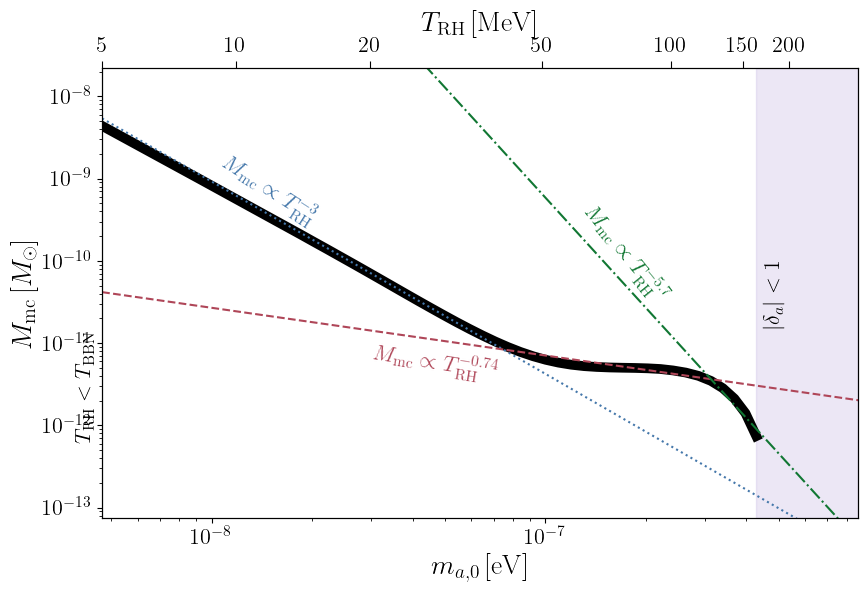

Low fit data: 5.0 -> 44.5854419 MeV
Mid fit data: 44.5854419 -> 123.801535 MeV
High fit data: 123.801535 -> 162.555431 MeV
Low-Mid intersection = 44.5854419 MeV
Mid-High intersection = 123.801535 MeV
low_p = -3.0
mid_p = -0.7442259389752998
high_p = -5.709498972615128
low_A / 1e-11 = 0.017353261293983527
mid_A / 1e-11 = 0.3203332088359671
high_A / 1e-11 = 0.13430723707059491


In [8]:
valid = np.isfinite(M_mc_solar_s) & (M_mc_solar_s > 0.0)

T_data = T_RH_s[valid] * 1e3
ma_data = ma0_s[valid]
mc_data = M_mc_solar_s[valid]

idx = np.argsort(T_data)
T_data = T_data[idx]
ma_data = ma_data[idx]
mc_data = mc_data[idx]

map_idx = np.argsort(T_RH_s)
T_map = T_RH_s[map_idx] * 1e3
ma_map = ma0_s[map_idx]

T_grid_mev = np.logspace(np.log10(T_map.min()), np.log10(T_map.max()), 500)
ma_grid = 10.0**np.interp(np.log10(T_grid_mev), np.log10(T_map), np.log10(ma_map))

ma_min = ma_grid.min()
ma_max = ma_grid.max()

fit_mask = T_data >= 5.0
T_fit = T_data[fit_mask]
ma_fit = ma_data[fit_mask]
mc_fit = mc_data[fit_mask]

gamma = np.polyfit(np.log10(T_grid_mev), np.log10(ma_grid), 1)[0]
low_p = -3.0
low_q = low_p / gamma

MIN_LOW = 6
MIN_MID = 6
MIN_HIGH = 4
LOW_BREAK_MIN = 20.0
LOW_BREAK_MAX = 45.0
MID_BREAK_MIN = 70.0
MID_BREAK_MAX = 150.0

best = None

for i in range(MIN_LOW - 1, len(T_fit) - MIN_MID - MIN_HIGH + 1):
    if T_fit[i] < LOW_BREAK_MIN or T_fit[i] > LOW_BREAK_MAX:
        continue

    x_low = np.log10(ma_fit[:i + 1])
    y_low = np.log10(mc_fit[:i + 1])
    c_low = np.mean(y_low - low_q * x_low)
    r_low = y_low - (c_low + low_q * x_low)

    ma1 = ma_fit[i]
    M1 = mc_fit[i]
    y1 = np.log10(M1)

    for j in range(i + MIN_MID - 1, len(T_fit) - MIN_HIGH):
        if T_fit[j] < MID_BREAK_MIN or T_fit[j] > MID_BREAK_MAX:
            continue

        x_mid = np.log10(ma_fit[i:j + 1] / ma1)
        y_mid = np.log10(mc_fit[i:j + 1] / M1)
        mid_q = np.sum(x_mid * y_mid) / np.sum(x_mid**2)
        mid_pred = y1 + mid_q * np.log10(ma_fit[i:j + 1] / ma1)
        r_mid = np.log10(mc_fit[i:j + 1]) - mid_pred

        ma2 = ma_fit[j]
        M2 = M1 * (ma2 / ma1)**mid_q
        y2 = np.log10(M2)

        x_high = np.log10(ma_fit[j:] / ma2)
        y_high = np.log10(mc_fit[j:] / M2)
        high_q = np.sum(x_high * y_high) / np.sum(x_high**2)
        high_pred = y2 + high_q * np.log10(ma_fit[j:] / ma2)
        r_high = np.log10(mc_fit[j:]) - high_pred

        score = np.mean(r_low**2) + np.mean(r_mid**2) + np.mean(r_high**2)

        if best is None or score < best[0]:
            best = score, i, j, c_low, mid_q, high_q

if best is None:
    raise RuntimeError("No se encontró una segmentación válida")

score, i_break, j_break, c_low, mid_q, high_q = best

T_low_end = T_fit[i_break]
T_mid_end = T_fit[j_break]

ma1 = ma_fit[i_break]
M1 = mc_fit[i_break]
ma2 = ma_fit[j_break]
M2 = M1 * (ma2 / ma1)**mid_q

mid_p = gamma * mid_q
high_p = gamma * high_q

low_C = 10.0**c_low
mid_C = M1 / ma1**mid_q
high_C = M2 / ma2**high_q

low_curve = low_C * ma_grid**low_q
mid_curve = mid_C * ma_grid**mid_q
high_curve = high_C * ma_grid**high_q

ma_150 = 10.0**np.interp(np.log10(150.0), np.log10(T_grid_mev), np.log10(ma_grid))
low_A = low_C * ma_150**low_q
mid_A = mid_C * ma_150**mid_q
high_A = high_C * ma_150**high_q

T_cross_low_mid = T_low_end
T_cross_mid_high = T_mid_end

colors = ["#4477AA", "#AF4658", "#DDCC77", "#117733"]

fig, ax = plt.subplots(figsize=(9, 6))

ax.plot(ma_data, mc_data, color="black", lw=7, zorder=1)
ax.plot(ma_grid, low_curve, color=colors[0], ls=":", lw=1.5, zorder=2)
ax.plot(ma_grid, mid_curve, color=colors[1], ls="--", lw=1.5, zorder=2)
ax.plot(ma_grid, high_curve, color=colors[3], ls="-.", lw=1.5, zorder=2)

ax.set_xscale("log")
ax.set_yscale("log")
ax.set_xlim(ma_min, ma_max)
ax.set_ylim(mc_data.min() * 0.1, mc_data.max() * 5.0)

def add_label(ax, x, y, i, text, color, shift):
    i0 = max(0, i - 5)
    i1 = min(len(x) - 1, i + 5)
    dx = np.log10(x[i1]) - np.log10(x[i0])
    dy = np.log10(y[i1]) - np.log10(y[i0])
    ax_dx = np.log10(ax.get_xlim()[1]) - np.log10(ax.get_xlim()[0])
    ax_dy = np.log10(ax.get_ylim()[1]) - np.log10(ax.get_ylim()[0])
    angle = np.degrees(np.arctan2((dy / ax_dy) * 6.0, (dx / ax_dx) * 9.0))
    ax.text(x[i], y[i] * shift, text, color=color, rotation=angle, ha="center", va="bottom", clip_on=True)

i_low = np.argmin(np.abs(T_grid_mev - 20.0))
i_mid = np.argmin(np.abs(T_grid_mev - 80.0))
i_high = np.argmin(np.abs(T_grid_mev - 135.0))

add_label(ax, ma_grid / 2.0, high_curve, i_high, fr"$M_{{\rm mc}}\propto T_{{\rm RH}}^{{{high_p:.1f}}}$", colors[3], 11.65)
add_label(ax, ma_grid / 2.0, low_curve * 2.2, i_low, r"$M_{\rm mc}\propto T_{\rm RH}^{-3}$", colors[0], 1.5)
add_label(ax, ma_grid / 3.8, mid_curve, i_mid, fr"$M_{{\rm mc}}\propto T_{{\rm RH}}^{{{mid_p:.2f}}}$", colors[1], 0.6)

y_center = 10.0**(0.5 * (np.log10(ax.get_ylim()[0]) + np.log10(ax.get_ylim()[1])))
ma_data_min = ma_data.min()
ma_data_max = ma_data.max()

ax.axvspan(ma_min, ma_data_min, color="#AEC6CF", alpha=0.4, zorder=-1)
ax.text(ma_data_min * 0.95, y_center * 0.07, r"$T_{\rm RH}<T_{\rm BBN}$", color="black", rotation=90, va="center", ha="right")

ax.axvspan(ma_data_max, ma_max, color="#C3B1E1", alpha=0.3, zorder=-1)
ax.text(ma_data_max * 1.05, y_center, r"$|\delta_a|<1$", color="black", rotation=90, va="center", ha="left")

ax.set_xlabel(r"$m_{a,0}\,[\mathrm{eV}]$")
ax.set_ylabel(r"$M_{\rm mc}\,[M_\odot]$")

top_ax = ax.twiny()
top_ax.set_xscale("log")
top_ax.set_xlim(ax.get_xlim())

T_ticks = np.array([5, 10, 20, 50, 100, 150, 200], dtype=float)
T_ticks = T_ticks[(T_ticks >= T_map.min()) & (T_ticks <= T_map.max())]
tick_pos = 10.0**np.interp(np.log10(T_ticks), np.log10(T_map), np.log10(ma_map))

top_ax.xaxis.set_major_locator(ticker.FixedLocator(tick_pos))
top_ax.xaxis.set_major_formatter(ticker.FixedFormatter([rf"${int(T)}$" for T in T_ticks]))
top_ax.xaxis.set_minor_locator(ticker.NullLocator())
top_ax.xaxis.set_minor_formatter(ticker.NullFormatter())
top_ax.tick_params(axis="x", which="major", direction="out", length=5, pad=4)
top_ax.tick_params(axis="x", which="minor", length=0)
top_ax.set_xlabel(r"$T_{\rm RH}\,[\mathrm{MeV}]$")

fig.subplots_adjust(left=0.13, right=0.97, bottom=0.13, top=0.88)
fig.savefig(plot_dir / "QCD_axion_eq_an.pdf", dpi=300)
plt.show()

print("Low fit data:", T_fit[0], "->", T_fit[i_break], "MeV")
print("Mid fit data:", T_fit[i_break], "->", T_fit[j_break], "MeV")
print("High fit data:", T_fit[j_break], "->", T_fit[-1], "MeV")
print("Low-Mid intersection =", T_cross_low_mid, "MeV")
print("Mid-High intersection =", T_cross_mid_high, "MeV")
print("low_p =", low_p)
print("mid_p =", mid_p)
print("high_p =", high_p)
print("low_A / 1e-11 =", low_A / 1e-11)
print("mid_A / 1e-11 =", mid_A / 1e-11)
print("high_A / 1e-11 =", high_A / 1e-11)
